# 03 — Cubo Sentinel da sub-AOI (Etapa 3)

Baixa composições **trimestrais** de Sentinel-2 L2A (12 bandas do TerraMind, Cloud Score+ ≥ 0,6) e Sentinel-1 GRD
(VV/VH em dB) para a sub-AOI de 16 × 16 patches (35,8 km) no Tapajós, 2019Q1–2025Q4, e guarda num cubo Zarr em `config.CUBE_DIR`.

- **Por que só uma sub-AOI:** o Tapajós inteiro daria ~330 GB só de S2. A sub-AOI serve para desenvolvimento,
  inspeção e depuração da normalização. Para as AOIs completas, a Etapa 4 baixa as mesmas composições bloco a
  bloco e passa direto pelo TerraMind, guardando só os embeddings.
- **Valores brutos no cubo:** S2 em DN L2A (uint16, 0 = sem dado), S1 em dB (float16, NaN = sem dado), e o número
  de observações limpas por pixel (`*_nobs`). A padronização do TerraMind é feita na leitura (`dados.normalize`).
- **Retomável:** cada (sensor, bloco, trimestre) é um chunk; se o Colab cair, rode de novo e ele continua.
- **Onde roda:** localmente (fluxo principal desde 29/10; o cubo vai para `data/`, ~5–8 GB, fora do git). No Colab, o
  cubo vai para o disco temporário da VM (`/content/cache`), **nunca para o Drive** (restam 2 GB). Pixels são um cache
  descartável: dá para refazer do Earth Engine.
- **Earth Engine local:** na primeira vez, rode `venv/Scripts/earthengine authenticate` no terminal (ou deixe a célula
  abaixo abrir o login no navegador).
- **Orçamento:** depois das primeiras tarefas, projeta o tamanho final e para se passar de `STORAGE_BUDGET_GB`.

Tempo esperado: ~1 h (2 sensores × 16 blocos × 28 trimestres = 896 requisições, 8 em paralelo); o gargalo é o Earth Engine e a conexão, não a máquina.

## 1. Setup

In [1]:
import sys, os, subprocess, time
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO_URL = 'github.com/GabrielPow/ProjetoGrassQuality.git'
BRANCH = 'main'
REPO_DIR = '/content/ProjetoGrassQuality'

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    try:
        from google.colab import userdata
        token = userdata.get('GITHUB_TOKEN')
    except Exception:
        token = None
    url = f'https://{token}@{REPO_URL}' if token else f'https://{REPO_URL}'
    if os.path.exists(REPO_DIR):
        subprocess.run(['git', '-C', REPO_DIR, 'pull', 'origin', BRANCH], check=True)
    else:
        subprocess.run(['git', 'clone', '-b', BRANCH, url, REPO_DIR], check=True)

    from importlib import metadata
    import numpy
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                    f'{REPO_DIR}/notebooks/gabriel/requirements-colab.txt'], check=True)
    if metadata.version('numpy') != numpy.__version__:
        print(f'numpy {numpy.__version__} -> {metadata.version("numpy")}: reiniciando o ambiente. '
              'Rode todas as células de novo (a instalação não se repete).')
        os.kill(os.getpid(), 9)
    os.chdir(f'{REPO_DIR}/notebooks/gabriel')
else:
    print('Local: setup do Colab pulado.')

Local: setup do Colab pulado.


In [2]:
import json
import numpy as np
import pandas as pd
import ee
import config, utils, rotulos, dados

try:
    ee.Initialize(project=config.EE_PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=config.EE_PROJECT_ID)
config.make_dirs()
utils.set_seed(config.SEED)
run_dir = utils.new_run('etapa3_cubo')
EPSG = config.AOIS['tapajos']['epsg']
CUBE = config.CUBE_DIR / config.CUBE_PATH_NAME
print('cubo:', CUBE, '| resumo:', run_dir)

cubo: C:\Users\gabri\Documents\ProjetoGrassQuality\data\cubo_tapajos_sub.zarr | resumo: C:\Users\gabri\Documents\ProjetoGrassQuality\results\etapa3_cubo\20261029-162434


## 2. Sub-AOI

A origem está fixada em `config.SUBAOI_ORIGIN` (escolhida em 29/10 por `dados.select_subaoi`, só com PRODES + DETER).
A célula abaixo refaz a seleção com os caches da Etapa 2 apenas para conferência: o cubo usa sempre a origem fixada.

In [3]:
grid = rotulos.make_grid('tapajos')
grid['split'] = rotulos.assign_blocks_to_splits(grid)
cache = config.LABELS_DIR / 'tapajos' / 'cache'
ev = pd.concat([rotulos.overlay_events(grid, rotulos.fetch_prodes('tapajos', cache)),
                rotulos.overlay_events(grid, rotulos.fetch_deter('tapajos', cache))], ignore_index=True)
cand = dados.select_subaoi(grid, ev, rotulos.normal_flags(ev, grid['patch_id'].values))
display(cand.head(5).round(2))
best = (int(cand.iloc[0]['bc']) * config.BLOCK_PATCHES, int(cand.iloc[0]['br']) * config.BLOCK_PATCHES)
if best != tuple(config.SUBAOI_ORIGIN):
    print(f'Aviso: com os dados de hoje a melhor janela seria {best}; mantendo a fixada {config.SUBAOI_ORIGIN}.')

sub = dados.subaoi_patches(grid)
print(len(sub), 'patches |', sub['split'].value_counts().to_dict(), '|',
      'lon', sub['lon'].min(), sub['lon'].max(), 'lat', sub['lat'].min(), sub['lat'].max())

,bc,br,normal,val,test,desmatamento,mineracao,fogo,degradacao,desmatamento_teste,mineracao_teste,fogo_teste,degradacao_teste,score
0,61,1028,0.31,True,True,113,67,72,35,61,35,69,19,67.18
1,61,1033,0.34,True,True,120,53,59,40,62,11,56,23,63.32
2,58,1030,0.32,True,True,116,57,86,26,50,20,83,6,63.19
3,58,1026,0.32,True,True,102,71,70,28,43,32,70,21,62.51
4,61,1027,0.40,True,True,90,56,79,34,47,31,76,21,61.73


256 patches | {'train': 192, 'val': 48, 'test': 16} | lon -56.56848 -56.26393 lat -7.12871 -6.82441


## 3. Estimativa de volume e teste de um bloco

Baixa um bloco num trimestre seco (2022Q3) e num chuvoso (2022Q1) para medir tempo, fração de pixels limpos e conferir valores antes do download completo.

In [4]:
n, t = len(sub), len(config.STEPS)
raw_gb = {'s2': n * t * len(config.S2_BANDS) * 224 * 224 * 2 / 1e9, 's1': n * t * len(config.S1_BANDS) * 224 * 224 * 2 / 1e9,
          'nobs': 2 * n * t * 224 * 224 / 1e9}
print('volume bruto (antes da compressão):', {k: round(v, 1) for k, v in raw_gb.items()}, '| total', round(sum(raw_gb.values()), 1), 'GB')

blk = sub.iloc[:16]
x0, y0 = int(blk['x0'].min()), int(blk['y0'].min())
probe = {}
for step in ['2022Q1', '2022Q3']:
    s, e = rotulos.step_bounds(step)
    for sensor in ['s2', 's1']:
        t0 = time.time()
        data, nobs = dados.fetch_block(sensor, x0, y0, EPSG, s.strftime('%Y-%m-%d'),
                                       (e + pd.Timedelta(days=1)).strftime('%Y-%m-%d'))
        clear = (nobs > 0).mean()
        valid = data[:, nobs > 0]
        probe[f'{sensor}_{step}'] = {'segundos': round(time.time() - t0, 1), 'frac_limpa': round(float(clear), 3),
                                     'obs_mediana': float(np.median(nobs[nobs > 0])) if clear else 0,
                                     'mediana_por_banda': np.round(np.nanmedian(valid, axis=1), 1).tolist() if clear else None}
for k, v in probe.items():
    print(k, v)

volume bruto (antes da compressão): {'s2': 8.6, 's1': 1.4, 'nobs': 0.7} | total 10.8 GB
s2_2022Q1 {'segundos': 53.0, 'frac_limpa': 0.997, 'obs_mediana': 4.0, 'mediana_por_banda': [443.0, 414.0, 544.0, 339.0, 789.0, 2365.0, 3034.0, 2989.0, 3346.0, 3384.0, 1595.0, 706.0]}
s1_2022Q1 {'segundos': 4.5, 'frac_limpa': 1.0, 'obs_mediana': 7.0, 'mediana_por_banda': [-7.599999904632568, -14.0]}
s2_2022Q3 {'segundos': 16.8, 'frac_limpa': 1.0, 'obs_mediana': 13.0, 'mediana_por_banda': [294.0, 307.0, 461.0, 260.0, 744.0, 2275.0, 2908.0, 2985.0, 3227.0, 3228.0, 1411.0, 584.0]}
s1_2022Q3 {'segundos': 4.6, 'frac_limpa': 1.0, 'obs_mediana': 6.0, 'mediana_por_banda': [-8.199999809265137, -14.5]}


Conferir antes de seguir: S2 em DN de reflectância (floresta: B4 ~200–400, B8 ~2500–3500), S1 em dB
(floresta: VV ~ −7, VH ~ −13), e a fração limpa do trimestre chuvoso bem menor que a do seco.

## 4. Download do cubo (retomável)

In [5]:
root = dados.open_cube(CUBE, sub, EPSG)
t0 = time.time()
dados.fill_cube(root, sub, EPSG, workers=8, cube_path=CUBE)
print(f'pronto em {(time.time() - t0) / 60:.0f} min | {dados.disk_gb(CUBE):.2f} GB em disco')

4 de 896 tarefas pendentes
  4/4  0.3 min  (~0 min restantes)
pronto em 0 min | 4.88 GB em disco


## 5. Disponibilidade de dados por trimestre

Fração dos patches com pelo menos `MIN_CLEAR_FRAC` (50%) de pixels observados. Abaixo disso o patch-trimestre é tratado como **dado faltante** nas etapas seguintes.

,2019Q1,2019Q2,2019Q3,2019Q4,2020Q1,2020Q2,2020Q3,2020Q4,2021Q1,2021Q2,...,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4
S2,0.98,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
S1,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


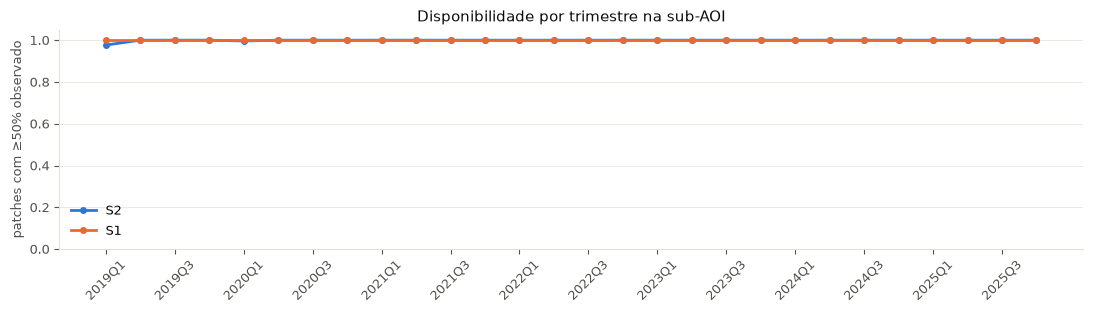

In [6]:
import matplotlib.pyplot as plt
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
S2_COLOR, S1_COLOR = '#2a78d6', '#eb6834'      # slots categóricos 1 e 2, sempre nessa ordem
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False})

clear = {s: dados.clear_fraction(root, s) for s in ['s2', 's1']}
avail = pd.DataFrame({s.upper(): (c >= config.MIN_CLEAR_FRAC).mean(axis=0) for s, c in clear.items()}, index=config.STEPS)
display(avail.T.round(2))

fig, ax = plt.subplots(figsize=(11, 3.2))
x = np.arange(len(config.STEPS))
for col, color in [('S2', S2_COLOR), ('S1', S1_COLOR)]:
    ax.plot(x, avail[col], color=color, lw=2, marker='o', ms=4, label=col)
ax.set_xticks(x[::2], config.STEPS[::2], rotation=45)
ax.set_ylim(0, 1.05); ax.set_ylabel(f'patches com ≥{config.MIN_CLEAR_FRAC:.0%} observado')
ax.grid(axis='y', color=GRID, lw=0.5); ax.legend(frameon=False, loc='lower left')
ax.set_title('Disponibilidade por trimestre na sub-AOI', color=INK)
fig.tight_layout(); fig.savefig(run_dir / 'disponibilidade.png', dpi=130); plt.show()

In [7]:
resumo = {'cubo': str(CUBE), 'gb_em_disco': round(dados.disk_gb(CUBE), 2), 'volume_bruto_gb': raw_gb,
          'n_patches': len(sub), 'splits': sub['split'].value_counts().to_dict(), 'origem': config.SUBAOI_ORIGIN,
          'teste_bloco': probe, 'tarefas_completas': int(root['done'][:].sum()),
          'disponibilidade_media': avail.mean().round(3).to_dict(),
          'trimestres_s2_abaixo_de_50pct': avail.index[avail['S2'] < 0.5].tolist()}
avail.to_csv(run_dir / 'disponibilidade.csv')
(run_dir / 'resumo.json').write_text(json.dumps(resumo, indent=2, default=str), encoding='utf-8')
print(json.dumps({k: resumo[k] for k in ['gb_em_disco', 'tarefas_completas', 'disponibilidade_media']}, indent=1))

{
 "gb_em_disco": 4.88,
 "tarefas_completas": 896,
 "disponibilidade_media": {
  "S2": 0.999,
  "S1": 1.0
 }
}
